# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Alice Miller, Emma Crawford, Nina Beadnell, Maciek Romanowski**

## Setup

In [1]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

In [2]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

This report investigates daily river water levels recorded at 392 monitoring stations across 35 counties in Scotland between 2014 and 2026. Using supervised and unsupervised machine learning techniques, we aim to identify meaningful patterns in river behaviour and investigate the potential for predicting flood events.

The data used in this report contains the river level monitoring stations (name and by ID label), their geographical location (county of Scotland, as well as longitude and latitude) and the reported daily average, minimum and maximum water levels (in metres). Before modelling, we analyse the data for missing observations, outliers and differences in station coverage. Relevant features are then constructed to describe river properties and aid further analysis.

Two objectives are considered, one concerning the overall behaviour of the water-level in rivers in Scotland, and the other trying to build a model to predict whether a flood will happen or not on a given day. 

First, we consider clustering, an unsupervised machine learning task where, based on the constructed features, we try to group together stations with similar properties. Clustering is crucial in identifying trends, patterns and intrinsic relationships in the dataset. We implement the K-means++ and hierarchical clustering algorithms and compare their performance. We observe that all stations can be grouped into three separate groups: one containing all of the tidal stations, [input rest].

Second, we consider classification, a supervised machine learning task, where we aim to build a model to predict future flood events. The approach used is to based our prediction on the preceeding 7 day, considering features like: [inster...] We train and test various models to find the one with the best performance. Given that flood events are rare, we choose as a baseline a model which always predicts no flood. Our best performing model is [insert model].

Building on our classification model, we identify factors that can be used to predict flood events. These findings can help government agencies understand river behaviour and identify regions at high risk of flooding. By predicting floods before they occur, we aim to ease the strain on government and emergency services, and reduce the human cost of flooding [reference 1]. On the other hand, the clustering model is useful for understanding general behaviours of the rivers, and potentially spotting ones where the risk of flooding is higher. 

# Exploratory Data Analysis and Feature Engineering

## Exploratory Data Analysis


Initial investigation of the data, seen in graph [Missing water-level observations across stations], indicates a significant proportion of the data is missing (30.64%). This is due to either the observation not being made, a particular observation station being decommissioned or not yet begun recording. Based on the heat map, we can see that almost no station have any recorded values before early 2017, and further analysis motivated the cut-off at [...]. We therefore decide to remove the first 908 days from out datasets.  It is also noted that the additional region of considerable missingness in 2021 is associated with the impact of Covid-19, which we kept in the dataset to maintain one continuous timeframe of investigation. Additionally we note the missingness of some dates, which we input as columns of NaNs to maintain a continuous time frame. We also ensured the dates ran in the correct chronological order. 


*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

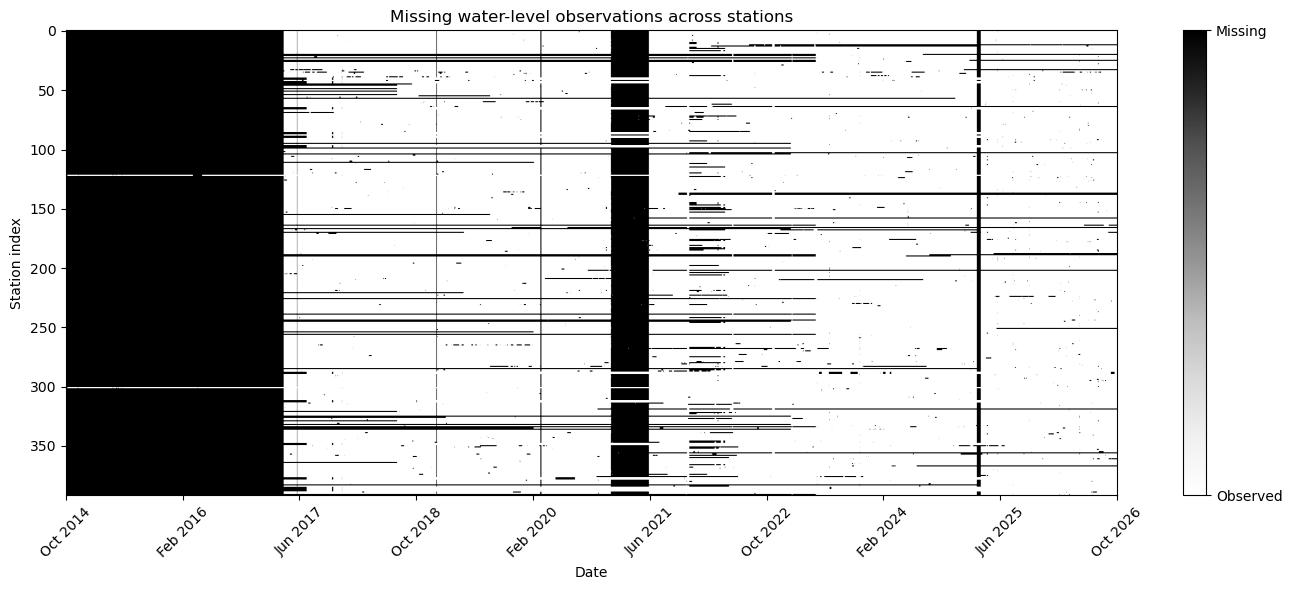

In [3]:
# Investigating the missing observations across different stations

# Select date columns
date_cols = df_avg.columns[3:]

data = df_avg[date_cols].apply(pd.to_numeric, errors="coerce")  # Make sure that the data has numerical values or NaN for missing values

# Convert columns to dates
data.columns = pd.to_datetime(date_cols, dayfirst=True)

# Sort chronologically and insert missing dates
data = data.sort_index(axis=1)

all_dates = pd.date_range(
    start=data.columns.min(),
    end=data.columns.max(),
    freq="D"
)

# If the date does NOT exist pandas creates a new column filled with NaN
data = data.reindex(columns=all_dates)

# Missing-data matrix: 1 = missing, 0 = observed
missing = data.isna().astype(int)

# Plot a heatmap
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(
    missing,
    aspect="auto",
    cmap="Greys"
)

# Date labels
ticks = np.linspace(0, len(all_dates) - 1, 10, dtype=int)

ax.set_xticks(ticks)
ax.set_xticklabels(
    all_dates[ticks].strftime("%b %Y"),
    rotation=45
)

ax.set_xlabel("Date")
ax.set_ylabel("Station index")
ax.set_title("Missing water-level observations across stations")

# Colourbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Observed", "Missing"])

plt.tight_layout()
plt.show()

We also identify "weird" values our in our data set, which could correspond to a different way of encoding missing data. Another reason for this might be the occurence of a flood event, when the equipement records abnormal values when the flood occurs. To account for this we decide to change all observation with values greater than absolute value of 30 to NaN. This allow to 


Potential outliers are present in the datasets, such as reports of river level exceeding 30m in elevation and falling below -30m, values that are simply impossible in context. This is likely due to human error, such as inputting an incorrect measure or misuse of or faulty measuring equipment. This led to the decision to ‘scrub’ these values from the data, and instead label them as no observation (NaN).

In [3]:
# Data preprocessing
def prepare_cluster(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    # Replace observations with |value| > 40 with NaN
    data = data.mask(data.abs() > 40)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(
        start=data.columns.min(),
        end=data.columns.max(),
        freq="D"
    )

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = prepare_cluster(df_avg)
minimum = prepare_cluster(df_min)
maximum = prepare_cluster(df_max)

We additionally note that only 12 stations in our dataset have tidal observations, which might be a useful gauge when analysing the clusteirng solution. One might expect a good clustering algorithm to be able to separate tidal stations from non-tidal ones. We decide to keep missing values as NaN instead of artificially imputing them. We considered interpolating when we have a 1 day gap, however in the end decided that this might cloud our analysis. All of our data preprocessing steps are contained within the data_prepare function, where we also transpose our dataframes, since having dates as rows is more convenient for Pandas [maybe reference]. We also verified that missing data is consistent across max, min and avg. 

## Feature Engineering

### Clustering

The first step of building any model is always feature engineering. We note that clustering and classification tasks are significantly different, and so will require different features to be considered. One of the main differences is that while for the clustering we use the whole data, for classification we use only te last preceeding 7 days, so it is sensible to build features depending on whole data for clustering but features depending only on 7 consecutive days for the classification task. 

The first step of building a clustering model is to select sensible features that allow the data to be clustered. In the datasets we are given stations and their respective mean, max and min water levels. Since these are on dependent on a specific river and its depth, these measures are not particualry well suited for the clustering proble, so we look for other possible measures. One such measure that immediately comes to mind is to try and quantify the variability of the water level at each station. The simplest way to do that is to look at the range of the data (i.e max - min) however that approach is easily skewed by outliers. As an example of that we can think of a river that has one flood event in the history. Using the range feature it might classify it together with rivers that have big water level variabilty, which would not be a good assigment. Similar problem goes for using standard deviation, which in this case is additionally amplified since we will later want to standardise the data. For that reason we believe that the interquartile range (IQR) is a good measure in this case, since it is resitant to outliers and will give a reliable measure of how variable the river is. Given that the risk of flooding is an important phenomenon we want to prevent we might also want to consider how extreme unusually high level are, which might help us identify stations where there is an often flooding occurence. On the flip side we might also want to look at how extreme unusually low level are, if we are looking at potential draughts. We might also want to consider the within-day variability and daily changes. On a larger scale we might want to consider the autocorrelation between different logged values to understand whether the water level fluctuation happen on short- or long- timescales. We know that different season are characterised by different amounts of rainfall, so seasonality might also play an important part. Finally we might want to add a feature that measures unsually large within-day fluctuations to distinguish between river with persistent large daily fluctuations and occasional (but extreme) ones. 

As the next step we investigate the correlation between the features to potemntially disregard features that are higly correlated, which might skwe our clustering algorithm. We can see that all measures of autocorreality are highly correlated, so we decide to keep only the weekly correlation which gives us the most unique information compared to other features. After that we want to standardise our data, since we are mostly interested in the variability of water levels and not general values of water levels.

In [8]:
# Define the features we want to use for the clustering problem 

# Interquartile range
iqr = avg.quantile(0.75) - avg.quantile(0.25)

# Upper-tail intensity
tail = (
    (avg.quantile(0.99) - avg.quantile(0.50))
    / iqr.where(iqr > 1e-8)
)

# Lower-tail intensity
tail_l = (
    (avg.quantile(0.50) - avg.quantile(0.01))
    / iqr.where(iqr > 1e-8)
)

# Within-day variability (where to account for possible NaN values)
daily_range = (maximum - minimum).where(maximum >= minimum)
R = daily_range.median()

# Daily changes
D = avg.diff().abs().median()

# Daily qutocorrelation
A1 = avg.corrwith(avg.shift(1))

# Weekly autocorrelation
AW = avg.corrwith(avg.shift(7))

# Monthly autocorrelation
AM = avg.corrwith(avg.shift(30))


# 7. Seasonal variation
first_half = avg[avg.index.month.isin([1, 2, 3, 4, 5, 6])].median()
second_half = avg[avg.index.month.isin([7, 8, 9, 10, 11, 12])].median()

S = first_half - second_half

# Construct feature matrix
X_cluster = pd.DataFrame({
    "IQR": iqr,
    "Upper_tail": tail,
    "Daily_range": R,
    "Daily_change": D,
    "Autocorr_1": A1,
    # "Autocorr_W": AW,
    # "Autocorr_M": AM,
    "Seasonality": S,
    "Lower_tail": tail_l,

})

print(X_cluster.head())

       IQR  Upper_tail  Daily_range  Daily_change  Autocorr_1  Seasonality  \
0  0.22875    3.666142       0.0130         0.009    0.909595       0.0345   
1  0.19725    3.219265       0.0500         0.030    0.747529      -0.0110   
2  0.39725    3.747111       0.0565         0.042    0.840708       0.0350   
3  0.24675    2.993110       0.0500         0.033    0.795250       0.0035   
4  0.34500    3.043188       0.0510         0.039    0.833367       0.0345   

   Lower_tail  
0    0.865574  
1    0.887199  
2    0.813090  
3    0.960932  
4    0.919275  


### Classification

The classification task is substantially different than clustering in nature. The goal is to predict is a flood will occur based on measurements from the previous 7 days. This creates issue like deciding what to do with NaN values, and what features to use. Another important thing to decide is how do we define a flood event? Since we are not given labels of when flood happened we need to come up with our own metric, which will naturally not be perfect. Expectation is that flood is a rare event, and an event where the water level gets exeptionally high. For that reason we decide to define a flood event, as an event in the 99th percentile of the training dataset. How to deal with NaN values? We came up with two ideas: the most obvious one is to just get rid of all NaN values. The issue is that in that case we lose the time continuity, and at each step we have to look at the column label to check if we are actually taking consecutive days. Our other idea, and the one that we are using, is to maintain temporal continuity and look for valid 8 day periods. By valid 8 day periods we mean 8 consecutive days with no missing measurements. We find that every station has over 400 valid periods, with almost all stations (-6) have over a 1000. We deem that enough data to build a working model, and proceed with that strategy. 

We then split the data in a way that keep a similar proportion of valid periods for both train and test data. We also want to make sure that both train and test sets have a similar proportion of flood events (both around 1%), especially since our data is highly imbalanced. Taking both of these thing into consideration we find that a roughly 80/20 split is great for this task and the split happens on the 2825. We do NOT want to randomise the data since we are dealing with a timeseries. 

Now that we have defined the flood event, assigned labels, and split the data into train and test it is time to look into what features to use. This is a highly non-trivial task, as it is not clear what features determines if it will flood. We also note that flood events often occur with a lot of stochasticity (eg. due to a large storm), so we do not expect to have incredible model performance. Even more, extremely precise model would be worrying, as it should not be possibe to perfectly predicts floods based on the last seven days. The simplest idea is to just use the mean value of the maximum water levels of the last 7 days. 


In [4]:
# Check whether given observation is valid for each dataset
valid = avg.notna() & minimum.notna() & maximum.notna()

# Check for 8 consecutive valid days (valid means no NaN values within these days)
# (we need 7 days from which we predict plus the 8th day on which we predict)
valid_8 = valid.rolling(8, min_periods=8).sum().eq(8)

# Count valid windows for each station and sort from the least number of valid periods
counts = valid_8.sum().sort_values()

In [5]:
# Split approximately 80/20 based on valid windows
valid_period_sum = valid_8.sum(axis=1).cumsum() # Calculate how many total valid 8-day periods are at each date
split = (valid_period_sum >= 0.8 * counts.sum()).argmax() + 1 # Calculate the date at whcih the train/test split happens

# Define flood events as observations in the 99th percentile of the station's observations
thresholds = maximum.iloc[:split].quantile(0.99).dropna()

# Identify floods
flood = maximum[thresholds.index] > thresholds

# Keep only valid 8-day windows
valid_flood = flood.where(valid_8[thresholds.index])

# Split using row positions
y_train = valid_flood.iloc[:split].stack().astype(int)
y_test = valid_flood.iloc[split:].stack().astype(int)

print("Training samples:", len(y_train))
print("Test samples:", len(y_test))
print("Training flood percentage:", 100 * y_train.mean())
print("Test flood percentage:", 100 * y_test.mean())
print(split)

Training samples: 932957
Test samples: 233205
Training flood percentage: 1.0220192356132167
Test flood percentage: 1.10803799232435
2825


# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    ConfusionMatrixDisplay
)

last = maximum.shift(1)
features = {
    "Mean_7d": maximum.shift(1).rolling(7).mean() - thresholds,
    "Last": maximum.shift(1) - thresholds,
    "Max_7d": maximum.shift(1).rolling(7).max() - thresholds,
    # "Change_1d": maximum.shift(1) - maximum.shift(2)

}

X = pd.concat(
    {name: df.stack() for name, df in features.items()},
    axis=1
).dropna()

X_train = X.loc[y_train.index]
X_test = X.loc[y_test.index]

from sklearn.svm import SVC

smc = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1,
        class_weight="balanced",
        random_state=0
    ))
])

smc.fit(X_train, y_train)

y_pred_test = smc.predict(X_test)
y_pred_train = smc.predict(X_train)

for name, y_true, y_pred in [
    ("Train", y_train, y_pred_train),
    ("Test", y_test, y_pred_test)
]:
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, zero_division=0))
    print("Recall:", recall_score(y_true, y_pred, zero_division=0))
    print("F1-score:", f1_score(y_true, y_pred, zero_division=0))

Last            2.263814
Mean_7d        -1.358066
Last_squared    0.941975
Range_7d        0.774664
Max_7d          0.709208
Std_7d         -0.458733
dtype: float64


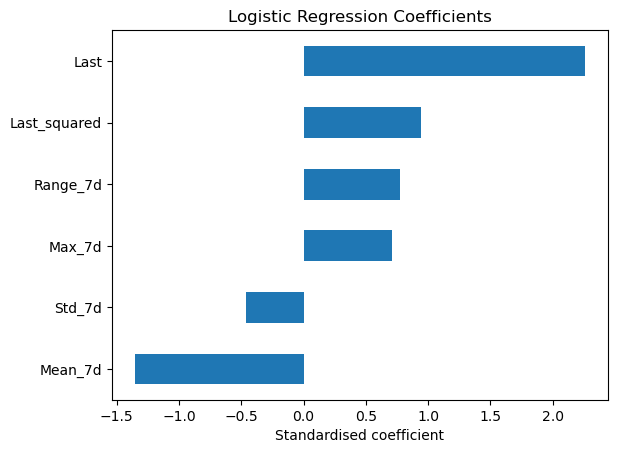


Train
Accuracy: 0.8422403176137807
Precision: 0.045602197250795576
Recall: 0.7243838489774514
F1-score: 0.08580284104672758

Test
Accuracy: 0.8610921721232392
Precision: 0.06024665132471824
Recall: 0.7902476780185759
F1-score: 0.11195789242831296


In [52]:
last = maximum.shift(1)
features = {
    "Mean_7d": maximum.shift(1).rolling(7).mean() - thresholds,
    "Last": maximum.shift(1) - thresholds,
    "Max_7d": maximum.shift(1).rolling(7).max() - thresholds,
    # "Change_1d": maximum.shift(1) - maximum.shift(2)

     # New features
    
    "Range_7d": last.rolling(7).max() - last.rolling(7).min(),
    "Std_7d": last.rolling(7).std(),
    "Last_squared": (last - thresholds) ** 2
}

X = pd.concat(
    {name: df.stack() for name, df in features.items()},
    axis=1
).dropna()

X_train = X.loc[y_train.index]
X_test = X.loc[y_test.index]


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight= "balanced",
        max_iter=1000,
        random_state=0
    ))
])

# Train the model
logistic.fit(X_train, y_train)

coef = pd.Series(
    logistic.named_steps["classifier"].coef_[0],
    index=X_train.columns
)

print(coef.sort_values(key=abs, ascending=False))

import matplotlib.pyplot as plt

coef.sort_values().plot.barh()
plt.xlabel("Standardised coefficient")
plt.title("Logistic Regression Coefficients")
plt.show()

# Make predictions
y_pred_train = logistic.predict(X_train)
y_pred_test = logistic.predict(X_test)

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    ConfusionMatrixDisplay
)

for name, y_true, y_pred in [
    ("Train", y_train, y_pred_train),
    ("Test", y_test, y_pred_test)
]:
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, zero_division=0))
    print("Recall:", recall_score(y_true, y_pred, zero_division=0))
    print("F1-score:", f1_score(y_true, y_pred, zero_division=0))


In [42]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=0
)

model.fit(X_train, y_train)

probs = model.predict_proba(X_test)[:, 1]

for name, y_true, y_pred in [
    ("Train", y_train, y_pred_train),
    ("Test", y_test, y_pred_test)
]:
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, zero_division=0))
    print("Recall:", recall_score(y_true, y_pred, zero_division=0))
    print("F1-score:", f1_score(y_true, y_pred, zero_division=0))


Train
Accuracy: 0.8457635239351867
Precision: 0.04655871811659253
Recall: 0.7234399580492921
F1-score: 0.08748699997463409

Test
Accuracy: 0.8623314251409704
Precision: 0.061365189741761014
Recall: 0.7991486068111455
F1-score: 0.11397819787498276


In [26]:
from sklearn.metrics import average_precision_score
probs = logistic.predict_proba(X_test)[:, 1]

print("Average precision:", average_precision_score(y_test, probs))

Average precision: 0.13553402236749185


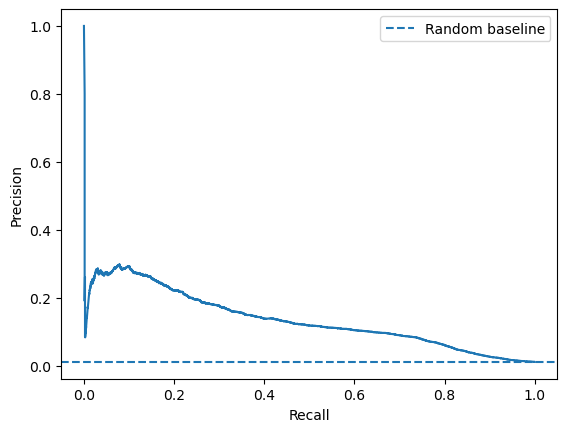

In [27]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

probs = logistic.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, probs)

plt.plot(recall, precision)
plt.axhline(y_test.mean(), linestyle="--", label="Random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

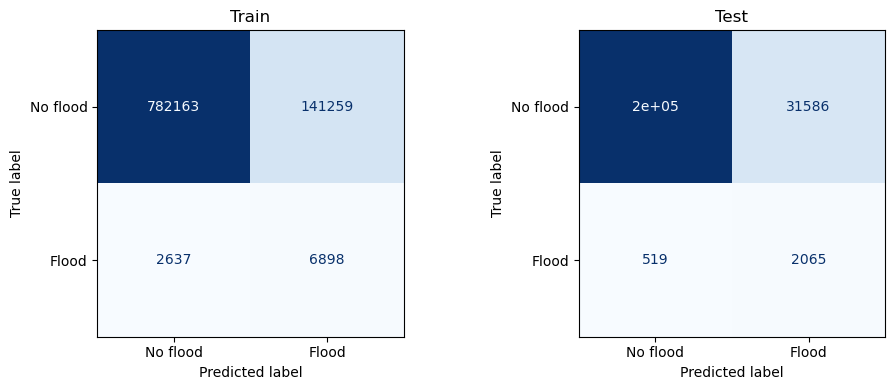

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, y_true, y_pred, title in zip(
    axes,
    [y_train, y_test],
    [y_pred_train, y_pred_test],
    ["Train", "Test"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        labels=[0, 1],
        display_labels=["No flood", "Flood"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

## Clustering 

Now that we have a feature matrix with carefully selected features we can move on to properly building our clustering model. We considered two different methods:  K-means ++ and hierarchical clustering. In the end we decided to use the hierarchical clusteirng as our final model, since it gave superior silhoutte score, which means that it separates clusters more accurately and there is less overlap. While the K-means++ worked very well in separating the tidal stations, it had poor performance in further clustering non-tidal stations. 

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler

# Standardise the same features used for K-means
X_scaled = StandardScaler().fit_transform(X_cluster)

# Hierarchical clustering using Ward's method
Z = linkage(X_scaled, method="ward")

# Plot dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    color_threshold=Z[-3, 2]  # Colour branches for approximately 4 clusters
)

plt.xlabel("Clusters / stations")
plt.ylabel("Ward linkage distance")
plt.title("Hierarchical clustering dendrogram")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

In [ ]:
k_values = range(2, 16)

scores_hierarchical = []

for k in k_values:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="average"
    )

    labels_h = model.fit_predict(X_scaled)

    scores_hierarchical.append(
        silhouette_score(X_scaled, labels_h)
    )

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    scores_hierarchical,
    marker="o",
    label="Hierarchical clustering"
)

plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Hierarchical clustering: silhouette analysis")
plt.xticks(list(k_values))
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Standardise the same features used for K-means
X_scaled = StandardScaler().fit_transform(X_cluster)

# Hierarchical clustering with 4 clusters
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

labels_hierarchical = hierarchical.fit_predict(X_scaled)

# Add cluster labels to the original feature matrix
X_hierarchical = X_cluster.copy()
X_hierarchical["Cluster"] = labels_hierarchical

# Number of stations in each cluster
print(X_hierarchical["Cluster"].value_counts().sort_index())

# Cluster characteristics
print("\nCluster means:")
print(X_hierarchical.groupby("Cluster").mean().round(3))

print("\nCluster medians:")
print(X_hierarchical.groupby("Cluster").median().round(3))

lallala

## Classification task

Given that the data is highly imbalanced and flood events occur very rarely, a natural choice for a baseline model is a dummy classifier that always predicts no flood. Such a model will have incredible accuracy, but at a cost of 0 precision, recall and f1-score. What is even more important, the answer of interest is when a flood will happen, as it matters a lot more than information of flood not happening. Thefore it is clear we must try to build more advanced models. 

# Interpretation, Discussion & Conclusions

## Clustering

The final clustering solution consists of 4 clusters. 

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [8]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] ERROR | Error while converting 'project.ipynb'
Traceback (most recent call last):
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\nbconvertapp.py", line 487, in export_single_notebook
    output, resources = self.exporter.from_filename(
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\templateexporter.py", line 386, in from_filename
    return super().from_filename(filename, resources, **kw)  # type:ignore[return-value]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\exporter.py", line 201, in from_filename
    return self.from_file(f, resources=resources, **kw)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\templateexporter.py", line 392, in from_file
    return su